# Week 6: Causal structures and regression

Module providing code for the modules.

# Preset

Run these cells first. They contain helper functions and generic imports.

In [ ]:
%pip install -q cmdstanpy==1.3.0

from pathlib import Path
import shutil
import urllib.request
import cmdstanpy
from cmdstanpy import CmdStanModel

CMDSTAN_VERSION = "2.39.0"
cmdstan_dir = Path(f"/content/cmdstan-{CMDSTAN_VERSION}")
archive_path = Path(f"/content/colab-cmdstan-{CMDSTAN_VERSION}.tgz")
archive_url = (
    f"https://github.com/stan-dev/cmdstan/releases/download/v{CMDSTAN_VERSION}/"
    f"colab-cmdstan-{CMDSTAN_VERSION}.tgz"
)
if not cmdstan_dir.exists():
    urllib.request.urlretrieve(archive_url, archive_path)
    shutil.unpack_archive(archive_path, "/content")
cmdstanpy.set_cmdstan_path(str(cmdstan_dir))


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit as inv_logit, logit
import networkx as nx

np.random.seed(6300)

In [ ]:
def bern(n, p=0.5):
    """Bernoulli draws."""
    return np.random.binomial(1, p, size=n)

def norm(n, mu=0, sigma=1):
    """Normal draws."""
    return np.random.normal(mu, sigma, size=n)

def corr(x, y):
    """Pearson correlation."""
    return np.corrcoef(x, y)[0, 1]

In [ ]:
# A generic multiple regression (with no predictive block since it is not used in this notebook)
stan_code = r"""
data {
  int<lower=1> N;
  int<lower=2> K;
  matrix[N, K] X;
  vector[N] y;
  real alpha_mean;
  real<lower=0> alpha_sd;
  real<lower=0> beta_sd;
}
parameters {
  vector[K] beta;
  real<lower=0> sigma;
}
model {
  beta[1] ~ normal(alpha_mean, alpha_sd);
  beta[2:K] ~ normal(0, beta_sd);
  sigma ~ exponential(1);
  y ~ normal_id_glm(X, 0, beta, sigma);
}
"""
stan_path = Path("linear_regression.stan")
stan_path.write_text(stan_code)
regression_model = CmdStanModel(stan_file=str(stan_path))


In [ ]:
def regress(y, X, alpha_sd=1, beta_sd=1, alpha_mean=0, **sample_kwargs):
    """Regress y on x with Stan. Takes care of shaping the design matrix."""
    y, X = np.asarray(y, dtype=float), np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X[:, None]
    design = np.column_stack([np.ones(len(y)), X])
    data = dict(N=len(y), K=design.shape[1], X=design, y=y,
                alpha_mean=alpha_mean, alpha_sd=alpha_sd, beta_sd=beta_sd)
    options = dict(chains=2, parallel_chains=2, iter_warmup=500,
                   iter_sampling=1000, seed=6300, inits=0, step_size=0.01,
                   show_progress=False)
    options.update(sample_kwargs)
    return regression_model.sample(data=data, **options)

In [ ]:
def _groups(n, z=None, label="Z"):
    groups = [("All observations", np.ones(n, dtype=bool))]
    if z is not None:
        z = np.asarray(z)
        groups += [(f"{label} = {value}", z == value) for value in (0, 1)]
    return groups

def table(x, y, z=None, label="Z"):
    """2 x 2 counts and correlations; rows are X, columns are Y."""
    x, y = np.asarray(x), np.asarray(y)
    x, y = x.astype(int), y.astype(int)
    for name, keep in _groups(len(x), z, label):
        counts = np.bincount(2 * x[keep] + y[keep], minlength=4).reshape(2, 2)
        print(f"{name}: n = {keep.sum()}, r = {corr(x[keep], y[keep]):.3f}")
        print("          Y = 0   Y = 1")
        for value in (0, 1):
            print(f"X = {value}   {counts[value, 0]:7d} {counts[value, 1]:7d}")
        print()


In [ ]:
def plot(x, y, z=None, label="Z", line=True):
    """Scatterplots with sample correlations."""
    x, y = np.asarray(x), np.asarray(y)
    groups = _groups(len(x), z, label)
    fig, axes = plt.subplots(1, len(groups), figsize=(4 * len(groups), 3.5),
                             sharex=True, sharey=True, squeeze=False)
    for i, (name, keep) in enumerate(groups):
        ax = axes[0, i]
        a, b = x[keep], y[keep]
        color = ["0.4", "tab:blue", "tab:orange"][i]
        ax.scatter(a, b, s=15, alpha=0.4, color=color)
        title = f"({chr(97 + i)}) {name}\nn = {len(a)}, r = {corr(a, b):.3f}"
        if line and len(a) > 1 and np.ptp(a) > 0:
            fit = regress(b, a)
            intercept, slope = fit.stan_variable("beta").mean(axis=0)
            grid = np.array([a.min(), a.max()])
            ax.plot(grid, intercept + slope * grid, color=color, lw=2)
            title += f", slope = {slope:.3f}"
        ax.set(xlabel="X", title=title)
    axes[0, 0].set_ylabel("Y")
    fig.tight_layout()
    plt.show()

In [ ]:
def dag(edges, pos=None):
    graph = nx.DiGraph(edges)
    if pos is None:
        pos = nx.spring_layout(graph, seed=6)
    plt.figure(figsize=(4, 3))
    nx.draw_networkx(graph, pos, node_color="white", edgecolors="black",
                     node_size=850, arrowsize=22, font_size=14)
    plt.axis("off")
    plt.show()
    return graph


# Binary and mixed simulations

## Fork

Let's start with the fork, which we write $X\leftarrow Z\to Y$.
Plotted with `networkx` we have

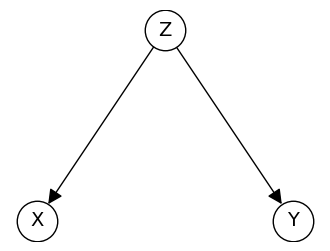

In [ ]:
dag([("Z", "X"), ("Z", "Y")], {"Z": (0, 1), "X": (-1, 0), "Y": (1, 0)});

### Binary

A binary fork:

In [ ]:
np.random.seed(1001)
n = 1000
Z = bern(n)
X = bern(n, 0.1 + 0.8 * Z)
Y = bern(n, 0.1 + 0.8 * Z)

In [ ]:
table(X, Y, Z)

All observations: n = 1000, r = 0.613
          Y = 0   Y = 1
X = 0       429      93
X = 1       100     378

Z = 0: n = 512, r = -0.068
          Y = 0   Y = 1
X = 0       426      43
X = 1        42       1

Z = 1: n = 488, r = -0.072
          Y = 0   Y = 1
X = 0         3      50
X = 1        58     377



We see a positive association between $X$ and $Y$ due to a common cause.
When we stratify by $Z$, the association is gone.

### Mixed

The simulation above uses binary variables to build intuitions in a simple case, but the same thing happens with continuous $X$ and $Y$.

In [ ]:
np.random.seed(1011)
n = 1000
Z = bern(n)
X = norm(n, 2 * Z - 1)
Y = norm(n, 2 * Z - 1)

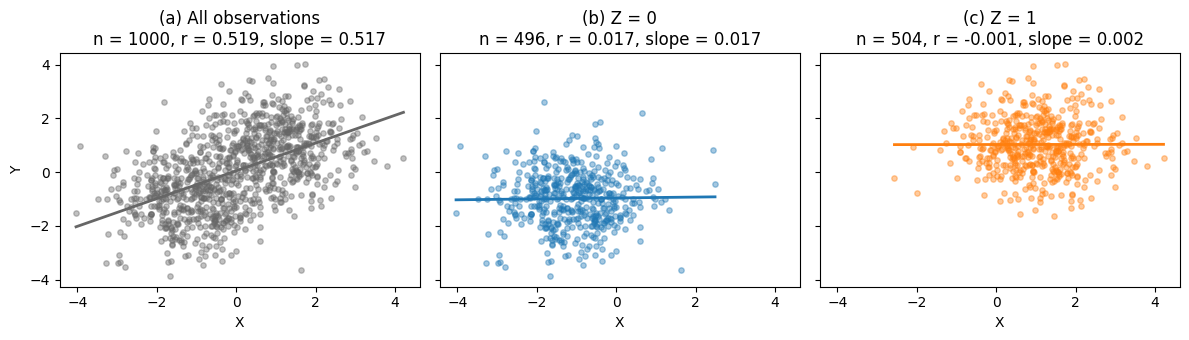

In [ ]:
plot(X, Y, Z)

## Pipe

Next we look at a pipe $X\to Z \to Y$, where $Z$ is called a mediator.

A plot with `networkx`:

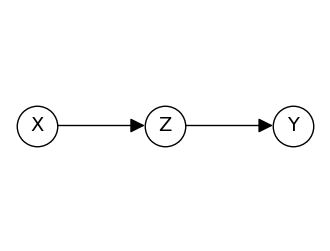

In [ ]:
dag([("X", "Z"), ("Z", "Y")], {"X": (-1, 0), "Z": (0, 0), "Y": (1, 0)});

### Binary

A binary pipe:

In [ ]:
np.random.seed(1002)
n = 1000
X = bern(n)
Z = bern(n, 0.1 + 0.8 * X)
Y = bern(n, 0.1 + 0.8 * Z)

In [ ]:
table(X, Y, Z)

All observations: n = 1000, r = 0.647
          Y = 0   Y = 1
X = 0       437      83
X = 1        93     387

Z = 0: n = 525, r = -0.053
          Y = 0   Y = 1
X = 0       432      43
X = 1        48       2

Z = 1: n = 475, r = 0.006
          Y = 0   Y = 1
X = 0         5      40
X = 1        45     385



$X$ and $Y$ are associated. Once we stratify / condition by $Z$, that association is gone.

### Mixed

Again, we can build towards a more realistic situation by considering a mixed model where $Z$ is discrete but both $X$ and $Y$ are continuous. The pipe is still in effect

In [ ]:
np.random.seed(1012)
n = 1000
X = norm(n)
Z = bern(n, inv_logit(X))  # inverse logit maps a real number to [0, 1] guaranteeing that we have a probability to parametrize Z
Y = norm(n, 2 * Z - 1)

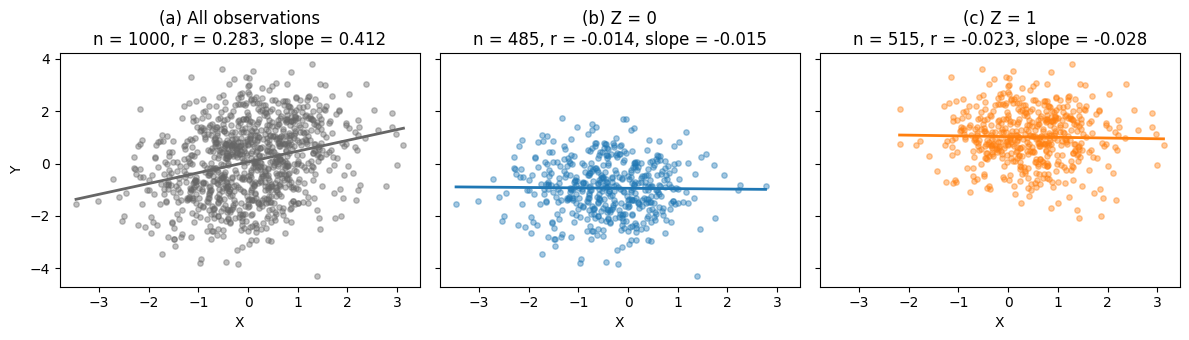

In [ ]:
plot(X, Y, Z)

Note how the pipe makes the same statistical predictions as the fork.
With the fork, the association arises because $Z$ influences both variables.
Accounting for $Z$ helps us avoid attributing that association to an effect of $X$.
In the pipe, $Z$ is precisely how $X$ influences $Y$.

## Collider

In a collider, $X$ and $Y$ are independent causes of a common *consequence*.

The `networkx` DAG is as follows:

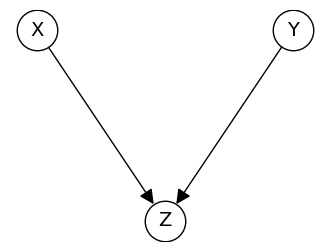

In [ ]:
dag([("X", "Z"), ("Y", "Z")], {"X": (-1, 1), "Y": (1, 1), "Z": (0, 0)});

### Binary

A binary collider is obtained by letting $Z$ depend on both $X$ and $Y$

In [ ]:
np.random.seed(1101)
n = 1000
X = bern(n)
Y = bern(n)
Z = bern(n, np.where(X + Y > 0, 0.9, 0.2))

In [ ]:
table(X, Y, Z)

All observations: n = 1000, r = -0.032
          Y = 0   Y = 1
X = 0       220     258
X = 1       257     265

Z = 0: n = 248, r = 0.408
          Y = 0   Y = 1
X = 0       165      26
X = 1        26      31

Z = 1: n = 752, r = -0.305
          Y = 0   Y = 1
X = 0        55     232
X = 1       231     234



$X$ and $Y$ are not associated in the first simulation.

Stratifying by $Z$ induces a correlation between the values, either positive or negative depending on the value of $Z$.

### Mixed

For the mixed simulation, we generate independent continuous causes and a binary collider.

In [ ]:
np.random.seed(1111)
n = 1000
X = norm(n)
Y = norm(n)
Z = bern(n, inv_logit(2 * X + 2 * Y - 2)) # inv_logit gets us a probability again

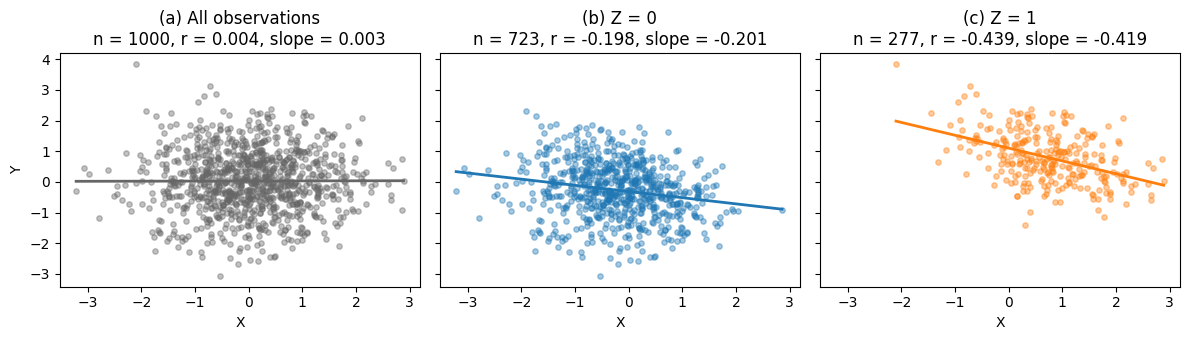

In [ ]:
plot(X, Y, Z)

## Descendants

A descendant of $Z$ is a variable we can reach by following one or more arrows in their direction, starting at $Z$.


It can descend from a pipe or a collider. For example, from a pipe:

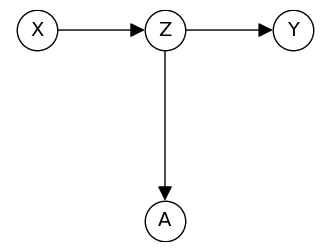

In [ ]:
dag([("X", "Z"), ("Z", "Y"), ("Z", "A")], {"X": (-1, 0), "Z": (0, 0), "Y": (1, 0), "A": (0, -1)});

### A descendant of a pipe: binary

We use the same binary pipe as before then generate one more variable, $A$.


In [ ]:
np.random.seed(1102)
n = 1000
X = bern(n)
Z = bern(n, 0.1 + 0.8 * X)
Y = bern(n, 0.1 + 0.8 * Z)
A = bern(n, 0.1 + 0.8 * Z)

In [ ]:
table(X, Y, A, label="A")

All observations: n = 1000, r = 0.664
          Y = 0   Y = 1
X = 0       436      87
X = 1        81     396

A = 0: n = 514, r = 0.354
          Y = 0   Y = 1
X = 0       381      46
X = 1        47      40

A = 1: n = 486, r = 0.500
          Y = 0   Y = 1
X = 0        55      41
X = 1        34     356



$X$ and $Y$ are associated in this simulation.

Conditioning on $A$ does not remove this association though it reduces it.

### A descendant of a pipe: mixed

The same thing happens in the mixed case.

In [ ]:
np.random.seed(1112)
n = 1000
X = norm(n)
Z = bern(n, inv_logit(X))
Y = norm(n, 2 * Z - 1)
A = bern(n, 0.1 + 0.8 * Z)

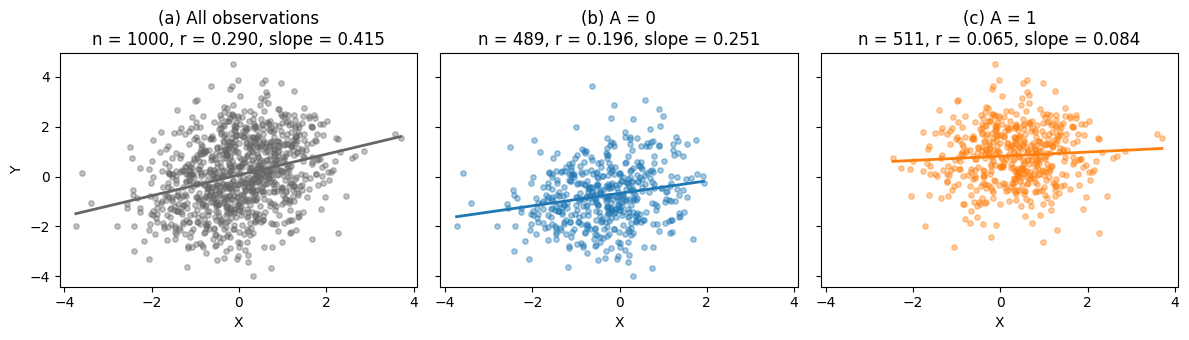

In [ ]:
plot(X, Y, A, label="A")

### A descendant of a collider: binary

Finally, let's attach $A$ to a collider instead.

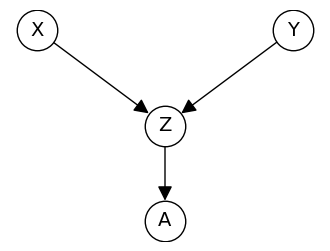

In [ ]:
dag([("X", "Z"), ("Y", "Z"), ("Z", "A")], {"X": (-1, 1), "Y": (1, 1), "Z": (0, 0), "A": (0, -1)});

In [ ]:
np.random.seed(1103)
n = 1000
X = bern(n)
Y = bern(n)
Z = bern(n, np.where(X + Y > 0, 0.9, 0.2))
A = bern(n, 0.1 + 0.8 * Z)

In [ ]:
table(X, Y, A, label="A")

All observations: n = 1000, r = -0.015
          Y = 0   Y = 1
X = 0       237     237
X = 1       271     255

A = 0: n = 317, r = 0.380
          Y = 0   Y = 1
X = 0       182      39
X = 1        43      53

A = 1: n = 683, r = -0.307
          Y = 0   Y = 1
X = 0        55     198
X = 1       228     202




In a collider conditioning on $Z$ induces an association between variables.
We create associations by conditioning on a descendent also, though the association is weaker than if we had conditioned on $Z$ directly:

In [ ]:

table(X, Y, Z)

All observations: n = 1000, r = -0.015
          Y = 0   Y = 1
X = 0       237     237
X = 1       271     255

Z = 0: n = 284, r = 0.475
          Y = 0   Y = 1
X = 0       192      24
X = 1        29      39

Z = 1: n = 716, r = -0.347
          Y = 0   Y = 1
X = 0        45     213
X = 1       242     216



### A descendant of a collider: mixed

And this happens in the mixed case also

In [ ]:
np.random.seed(1113)
n = 1000
X = norm(n)
Y = norm(n)
Z = bern(n, inv_logit(2 * X + 2 * Y - 2))
A = bern(n, 0.1 + 0.8 * Z)

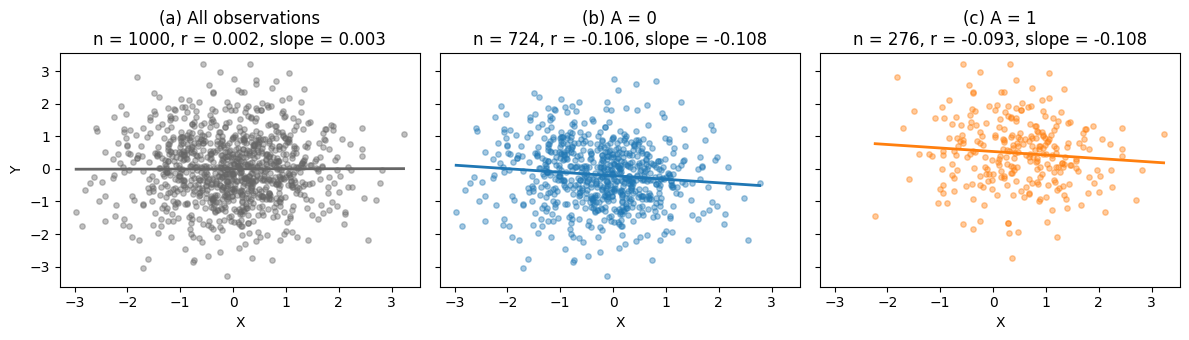

In [ ]:
plot(X, Y, A, label="A")

## What if the common cause is continuous?

So far, we have stratified with a binary $Z$, by splitting the data into two groups.
Within each group, we calculated the association of $X$ and $Y$ while keeping the cause constant.
But what does it mean to stratify when $Z$ is continuous?
We may only have a few (or no) observations with exactly the same value of $Z$, so direct data splits cannot be used.

Our goal is still to compare $X$ and $Y$ at the same value of $Z$.
For continuous causes, we do this by modeling how the distribution of $Y$ depends on both variables.

In [ ]:
np.random.seed(1003)
n = 1000
Z = norm(n, 0, 1)
X = norm(n, Z, 1)
Y = norm(n, Z, 1)

To account for their common cause, we compare a simple regression to the familiar multiple regression model:

$$Y_i\mid X_i,\theta\sim N(\alpha+\beta_X X_i,\sigma).\tag{Model 1}$$
$$Y_i\mid X_i,Z_i,\theta\sim N(\alpha+\beta_X X_i+\beta_Z Z_i,\sigma).\tag{Model 2}$$

In [ ]:
fit1 = regress(Y, X)
fit2 = regress(Y, np.column_stack([X, Z]))

Model 2 describes an infinite family of parallel lines, one for each value of $Z$.

We are fixing the common cause $Z$ and are asking about the association of $X$ and $Y$.

Ergo: Multiple regression stratifies the data!

So if we look at the posterior distribution of $\beta_X$ in Model 1 vs Model 2, we will have equivalently a model where we don't remove the effect of $X$ on $Y$ and one where we do.

The result can be visualized by showing the posterior distribution of $\beta_X$.
We have a continuous fork!

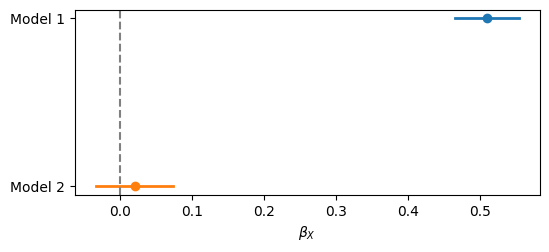

In [ ]:
plt.figure(figsize=(6, 2.4))
for row, (label, fit) in enumerate([("Model 1", fit1), ("Model 2", fit2)]):
    b = fit.stan_variable("beta")[:, 1]
    lo, hi = np.quantile(b, [0.05, 0.95])
    plt.plot([lo, hi], [row, row], color=f"C{row}", lw=2)
    plt.plot(b.mean(), row, "o", color=f"C{row}")
plt.yticks([0, 1], ["Model 1", "Model 2"])
plt.gca().invert_yaxis()
plt.axvline(0, color="0.5", linestyle="--")
plt.xlabel(r"$\beta_X$")
plt.show()

Accounting for the common cause moves the estimated $X$ coefficient towards zero, consistent with the prediction of the fork.

# Applied regression studies

Applied regression studies done in the notes.

## Fork: marriage and divorce

This study uses the `WaffleDivorce` dataset distributed with the `rethinking` package, which contains population-level observations about marriage, for 49 states and the District of Columbia.
We'll use divorce rate $D$, marriage rate $M$, and median age at marriage $A$.

Source: McElreath's [WaffleDivorce.csv](https://github.com/rmcelreath/rethinking/blob/ac1b3b2cda83f3e14096e2d997a6e30ad109eeee/data/WaffleDivorce.csv).

In [ ]:
divorce_url = (
    "https://raw.githubusercontent.com/rmcelreath/rethinking/"
    "ac1b3b2cda83f3e14096e2d997a6e30ad109eeee/data/WaffleDivorce.csv"
)
divorce_path = Path("WaffleDivorce.csv")
urllib.request.urlretrieve(divorce_url, divorce_path)
divorce = np.genfromtxt(divorce_path, delimiter=";", names=True, dtype=None, encoding="utf-8")


In [ ]:
A_raw = divorce["MedianAgeMarriage"]
M_raw = divorce["Marriage"]
D_raw = divorce["Divorce"]


To ease the analysis, all three variables are centered and divided by their sample standard deviations.
Thus, a one-unit difference means a difference of one sample standard deviation.

In [ ]:
A = (A_raw - A_raw.mean()) / A_raw.std(ddof=1)
M = (M_raw - M_raw.mean()) / M_raw.std(ddof=1)
D = (D_raw - D_raw.mean()) / D_raw.std(ddof=1)
print(f"{len(D)} observations; A, M, and D are ready.")


50 observations; A, M, and D are ready.


All variables are associated. We need a model to make sense of this.

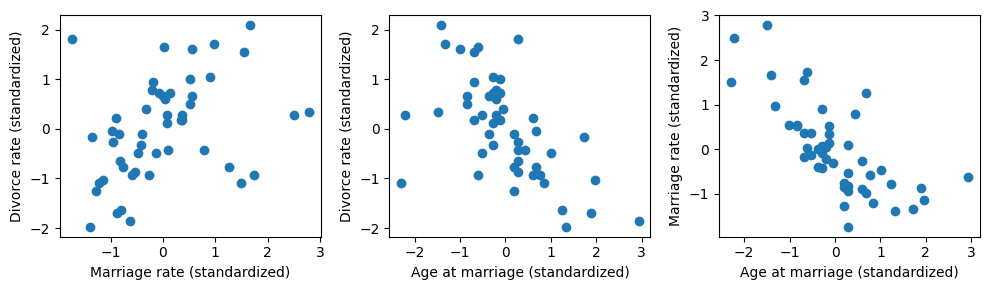

In [ ]:
plt.figure(figsize=(10,3))
plt.subplot(131)
plt.scatter(M, D)
plt.xlabel("Marriage rate (standardized)")
plt.ylabel("Divorce rate (standardized)")

plt.subplot(132)
plt.scatter(A, D)
plt.xlabel("Age at marriage (standardized)")
plt.ylabel("Divorce rate (standardized)")

plt.subplot(133)
plt.scatter(A, M)
plt.xlabel("Age at marriage (standardized)")
plt.ylabel("Marriage rate (standardized)")

plt.tight_layout()

Let's say our goal is to understand which of these variables has a causal effect on $D$.
We can make up several stories about this data, but let's consider a fork, that age at marriage influences both rates:
$$M\leftarrow A\to D.$$
In this story, any association between marriage rate and divorce would have to come from a common cause, $A$.
Locations where people marry younger would have both more marriages and more divorces, which would associate the two rates even without an additional influence from $M$ to $D$.

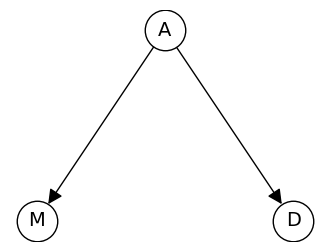

In [ ]:
dag([("A", "M"), ("A", "D")], {"A": (0, 1), "M": (-1, 0), "D": (1, 0)});

We do this by fitting two regressions to the response $D$:

$$D_i\mid M_i,\theta\sim N(\alpha+\beta_M M_i,\sigma).\tag{Model 3}$$
$$D_i\mid M_i,A_i,\theta\sim N(\alpha+\beta_M M_i+\beta_A A_i,\sigma).\tag{Model 4}$$

In [ ]:
fit3 = regress(D, M, alpha_sd=0.2, beta_sd=0.5)
fit4 = regress(D, np.column_stack([M, A]), alpha_sd=0.2, beta_sd=0.5)

In [ ]:
fit4.summary()

,Mean,MCSE,StdDev,MAD,5%,50%,95%,ESS_bulk,ESS_tail,ESS_bulk/s,R_hat
lp__,-17.187500,0.053649,1.521980,1.353650,-20.044700,-16.879100,-15.401100,784.823,1320.42,8261.29,1.000940
beta[1],0.000237,0.002307,0.102544,0.101062,-0.165982,0.000577,0.170148,2005.150,1480.69,21106.80,0.999867
beta[2],-0.066627,0.004714,0.165208,0.163209,-0.333578,-0.068251,0.209518,1243.850,1376.14,13093.10,1.000880
beta[3],-0.610371,0.004761,0.164475,0.162795,-0.863341,-0.614567,-0.323032,1218.110,1319.78,12822.20,1.000690
sigma,0.827596,0.002048,0.089159,0.086635,0.698946,0.820960,0.986521,1918.300,1163.86,20192.60,0.999615


Accounting for age at marriage removes most of the estimated association with marriage rate, as is confirmed by the stacked posterior plot

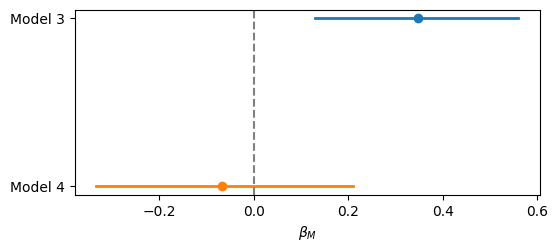

In [ ]:
plt.figure(figsize=(6, 2.4))
for row, (label, fit) in enumerate([("Model 3", fit3), ("Model 4", fit4)]):
    b = fit.stan_variable("beta")[:, 1]
    lo, hi = np.quantile(b, [0.05, 0.95])
    plt.plot([lo, hi], [row, row], color=f"C{row}", lw=2)
    plt.plot(b.mean(), row, "o", color=f"C{row}")
plt.yticks([0, 1], ["Model 3", "Model 4"])
plt.gca().invert_yaxis()
plt.axvline(0, color="0.5", linestyle="--")
plt.xlabel(r"$\beta_M$")
plt.show()

## Pipe: a treatment that works through a mediator

For the demonstration of the pipe, we use a *simulated* experiment where we control the data generating process.

In this experiment, we suppose that we randomly assign 100 plants to two groups of 50.
One group receives an antifungal treatment, and the other is kept as a control, which we code as $T=1$ or $T=0$, respectively.
We then observe whether any fungus is present after a suitable amount of time (coded $F\in\{0,1\}$).
We also measure plant growth in $G$ centimeters.

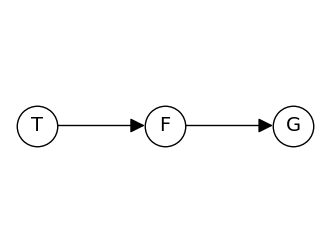

In [ ]:
dag([("T", "F"), ("F", "G")], {"T": (-1, 0), "F": (0, 0), "G": (1, 0)});

The following simulation code represents our assumptions

In [ ]:
np.random.seed(71)
n = 100
T = np.repeat([0, 1], n // 2)
np.random.shuffle(T)

In [ ]:
F = bern(n, 0.5 - 0.4 * T)
G = norm(n, 5 - 3 * F, 1)

We can check the predictions of the pipe by fitting two normal regressions:

$$G_i\mid T_i,\theta\sim N(\alpha+\beta_T T_i,\sigma).\tag{Model 1}$$
$$G_i\mid T_i,F_i,\theta\sim N(\alpha+\beta_T T_i+\beta_F F_i,\sigma).\tag{Model 2}$$

In [ ]:
plant1 = regress(G, T, alpha_mean=5, alpha_sd=2, beta_sd=2)
plant2 = regress(G, np.column_stack([T, F]), alpha_mean=5, alpha_sd=2, beta_sd=2)

In [ ]:
plant2.summary()

,Mean,MCSE,StdDev,MAD,5%,50%,95%,ESS_bulk,ESS_tail,ESS_bulk/s,R_hat
lp__,-54.732200,0.049754,1.402630,1.180950,-57.556900,-54.411100,-53.076200,868.432,1126.630,4115.79,1.00328
beta[1],5.264400,0.007517,0.202115,0.198560,4.929350,5.265820,5.598560,728.173,961.495,3451.06,1.00159
beta[2],-0.209155,0.007980,0.236838,0.232758,-0.592396,-0.213153,0.184764,881.202,1056.780,4176.31,1.00133
beta[3],-3.290200,0.008662,0.259447,0.256693,-3.701330,-3.291670,-2.857560,901.932,1099.320,4274.56,1.00113
sigma,1.024880,0.001865,0.073999,0.071241,0.909515,1.020500,1.149100,1572.450,983.451,7452.35,1.00235


Comparing posterior means and 90% intervals for $\beta_T$.
The dotted line marks the known true overall effect of $1.2$ cm (set in our simulations)

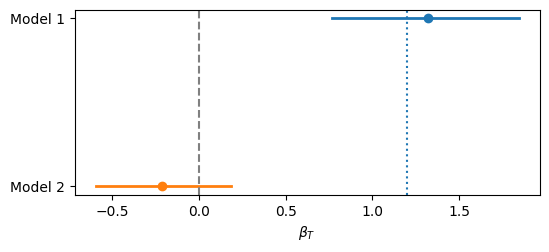

In [ ]:
plt.figure(figsize=(6, 2.4))
for row, (label, fit) in enumerate([("Model 1", plant1), ("Model 2", plant2)]):
    b = fit.stan_variable("beta")[:, 1]
    lo, hi = np.quantile(b, [0.05, 0.95])
    plt.plot([lo, hi], [row, row], color=f"C{row}", lw=2)
    plt.plot(b.mean(), row, "o", color=f"C{row}")
plt.yticks([0, 1], ["Model 1", "Model 2"])
plt.gca().invert_yaxis()
plt.axvline(0, color="0.5", linestyle="--")
plt.axvline(1.2, color="C0", linestyle=":")
plt.xlabel(r"$\beta_T$")
plt.show()

The treatment coefficient moves towards zero when we include $F$ as a predictor.
That is a correct answer to an incorrect question!
Among plants with the same fungus status, treatment has no further influence in this generating model.
It would be the wrong answer to the question of whether the treatment improves growth overall, because we have accounted for the mechanism that makes the treatment work.

## Collider: selection is conditioning, too

In this demonstration of the collider, we use simulated data again.
We imagine that grant proposals are evaluated on perceived impact $I$ and scientific trustworthiness $T$.

In the simulated population, we suppose these qualities are independent standard normal variables and that the overall score a proposal gets is
$$S_i\mid I_i,T_i\sim N(I_i+T_i,0.5).$$

That is, the score is centered around $I_i+T_i$ with some error.
We have a collider structure because $I\rightarrow S\leftarrow T$.

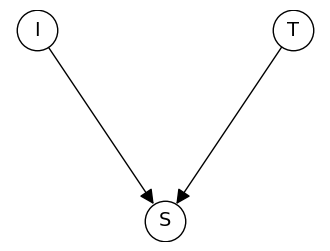

In [ ]:
dag([("I", "S"), ("T", "S")], {"I": (-1, 1), "T": (1, 1), "S": (0, 0)});

Simulating a population of 400 proposals:

In [ ]:
np.random.seed(1914)
n = 400
I = norm(n)
T = norm(n)
S = norm(n, I + T, 0.5)

Suppose we want to assess what drives the trustworthiness $T$ of a proposal in the complete population.
Let's compare what two regression models for $T$ have to say:

$$T_i\mid I_i,\theta\sim N (\alpha+\beta_I I_i,\sigma).\tag{Model 3}$$
$$T_i\mid I_i,S_i,\theta\sim N(\alpha+\beta_I I_i+\beta_S S_i,\sigma).\tag{Model 4}$$

In [ ]:
proposal3 = regress(T, I)
proposal4 = regress(T, np.column_stack([I, S]))

In [ ]:
proposal4.summary()

,Mean,MCSE,StdDev,MAD,5%,50%,95%,ESS_bulk,ESS_tail,ESS_bulk/s,R_hat
lp__,107.505000,0.046283,1.401090,1.276690,104.818000,107.798000,109.148000,940.663,1334.29,5468.97,0.999850
beta[1],-0.017036,0.000559,0.023813,0.023836,-0.056090,-0.017285,0.022503,1839.010,1248.63,10691.90,1.000090
beta[2],-0.768597,0.000715,0.030135,0.029304,-0.817276,-0.767761,-0.719454,1807.310,1262.62,10507.60,1.000690
beta[3],0.773377,0.000504,0.020092,0.019252,0.738989,0.774097,0.806068,1604.800,1390.01,9330.25,1.000630
sigma,0.461803,0.000367,0.015972,0.015699,0.435005,0.461866,0.488048,1916.210,1432.47,11140.80,0.999826


We compare posterior means and 90% intervals for $\beta_I$.

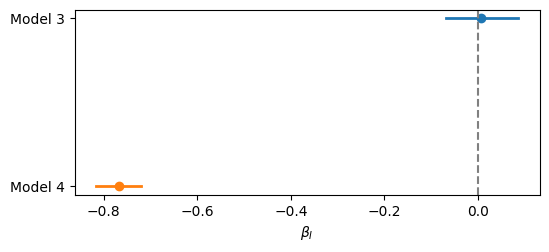

In [ ]:
plt.figure(figsize=(6, 2.4))
for row, (label, fit) in enumerate([("Model 3", proposal3), ("Model 4", proposal4)]):
    b = fit.stan_variable("beta")[:, 1]
    lo, hi = np.quantile(b, [0.05, 0.95])
    plt.plot([lo, hi], [row, row], color=f"C{row}", lw=2)
    plt.plot(b.mean(), row, "o", color=f"C{row}")
plt.yticks([0, 1], ["Model 3", "Model 4"])
plt.gca().invert_yaxis()
plt.axvline(0, color="0.5", linestyle="--")
plt.xlabel(r"$\beta_I$")
plt.show()

Model 4 includes the score as a predictor and therefore stratifies the data by scores.
As such, $\beta_I$ has to explain the relationship between $T$ and $I$ for groups of proposals that have the same score.
By attempting to control for too many variables, we have introduced a selection issue: Grants of a certain score get this score either because they are trustworthy or impactful.
This type of model misspecification is called a **collider bias**.

Note that there is nothing wrong with the regression calculation itself.
At a fixed score, higher perceived impact does predict lower trustworthiness and the regression estimates this conditional relationship correctly.
The error would be giving its coefficient a causal interpretation.